# Quantum Metal iSWAP example 3 — two crossmons and a tunable coupler, open readouts beside a through line (Quantcore PDK rebuild)

**What the chip is.** Example 3 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. X 11,
021058 (2021), Fig. 1; the same qubit / coupler pair as `D.Qubit-couplers/31-TwoCrossmonsTunableCoupler`; © IBM /
Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/iswap3_xmon_tc.md`; the notebook: "the point is the structure of each device, not its exact
geometry"). Two `TransmonCrossFL` crossmons 600 µm apart with a `TunableCoupler01` (C-shaped interdigitated island
with a SQUID and a flux line) above their inner arms. An east–west through line arches over the chip; the two
qubits' 2 mm readout meanders and the coupler's 1.5 mm meander end open (`OpenToGround`) next to it. Six
launchpads: the two through-line ends, Q1's flux line, a line on Q2's claw `b`, Q1's claw `b` and the coupler's flux
line. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 3 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 4 × 3 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die, the source's chip area centred in it, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | six `LaunchpadWirebond`s on the 4 × 3 mm chip's edges (≈ 2–2.5 mm inside the die) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge they face (W, E, N, N, S, S); their lines get longer leads |
| junctions | Metal junction lines (10 nH assumed) | Quantcore trilayer SQUIDs (PDK: two 0.25 × 0.6 µm junctions, 45 kΩ in parallel) for both crossmons and the coupler |
| crossings | the two north lines cross the arch (a short in the source's mask) | a KQC airbridge at each crossing |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteStraight` / `RouteMeander` (1.5 / 2 / 2 mm, 40 µm fillet) | qcc `cpw` routes on Metal's corner points (lengths kept; the pad leads grow) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options and relative positions, every route's end pins and
Metal's corner points (`RouteStraight` lines with their 250 µm leads, the three `RouteMeander`s with 90 µm spacing and
40 µm fillet: 1500 / 2000 / 2000 µm). All routes are 10/6 µm CPW (Metal's defaults).

**Simplified:** (1) Metal's through line (`RouteMeander` with six jogs) overshoots the west launchpad's tie and
doubles back to it (714 µm doubled stub under the pad in the source's screenshot); the rebuild ends the arch at the
tie. (2) The straight lines get a 20 µm fillet at their 45° corners (Metal draws them sharp). (3) The lines to the two
north pads cross the arch: each gets a KQC airbridge at the crossing (none in the source).

**Assumed couplings:** the coupler island's ends sit over the qubits' inner arms, and the inner arm tips face each
other across 200 µm; no route carries these, so they are declared with `d.couple` from coplanar-strip estimates
(rough). The Q3D job `Q1_TC_Q2` replaces them. The readout ends couple to the through line only through their 125 µm
gap to it (≈ 0.1 fF): not in the LOM, so their κ comes from the eigenmode job.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the six launchpads, the through line with the three open ends beside it, the two
crossmons, their open readout meanders, the coupling (the tunable coupler, its meander and the declared couplings),
the four control lines with their airbridges, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `iswap3_xmon_tc.v1.ipynb`; both save the same
`iswap3_xmon_tc.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.lom import estimates as est
CPW = dict(a=10, b=6)                            # Metal cpw_width / cpw_gap defaults

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame; the six launchpads go 100 µm from the edges they face; both crossmons and the coupler get a PDK trilayer SQUID; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the through line is drawn as soon as its two pads exist
(segment 3), each meander once its claw is there (segments 5–6), the control lines last (segment 7).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame, the source's 4 × 3 mm chip centred in it |
| 2 | the six launchpads (W, E, two N, two S) |
| 3 | the readout line: the east–west through line (Metal's arch) and the three `OpenToGround` ends beside it |
| 4 | the two `TransmonCrossFL` crossmons with PDK SQUIDs |
| 5 | the two 2 mm open readout meanders, claw → open end |
| 6 | the coupling: the tunable coupler with its SQUID, its 1.5 mm meander, three declared couplings |
| 7 | the control routing: four straight lines to the N / S pads, two of them bridged over the arch |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
source's 4 × 3 mm chip fits the 7.5 mm Quantcore die, so the die is centred on it: `box=(-1750, -2250, 5750, 5250)`.
Metal centres its chip on (0, 0), so a Metal position (x, y) is `P(x, y)` = (2000 + x, 1500 + y) here.

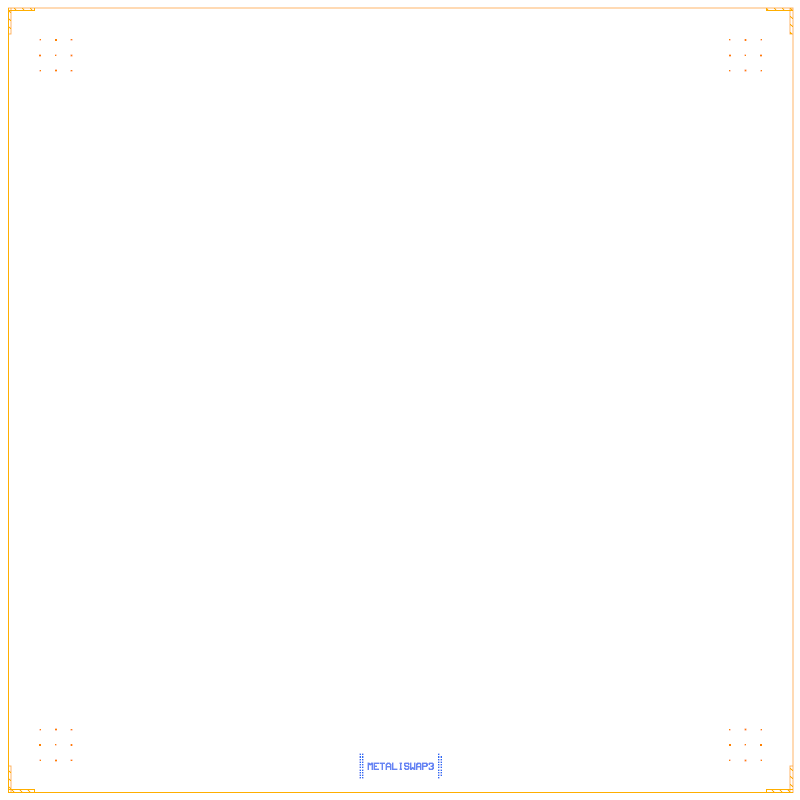

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s1_die.png')

In [5]:
d = Designer("iswap3_xmon_tc", box=(-1750, -2250, 5750, 5250), chip={"name_chip": "MetalISWAP3"}, live=LIVE)
X0, Y0 = 2000, 1500                              # Metal's 4 × 3 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
layout_step(d, OUT / "iswap3_xmon_tc_s1_die.png", size=(800, 800), width=320)

## Design 2 · Bond pads: the PDK pad rule

The tutorial's six `LaunchpadWirebond`s sit on the edges of its 4 × 3 mm chip, 2–2.5 mm inside our die: the two
through-line pads point west / east, the four control pads north (`T_NE`, `T_NW`) and south (`T_SW`, `T_SE`). In the
Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**:
`edge="w"` / `"e"` / `"n"` / `"s"` slides each pad perpendicular to the edge it faces until it is there, keeping its
position along that edge (here `"auto"` would pick the same edges). The lines are routed to the pads' ties later, so
their last straight lead simply gets longer.

The table measures it on the built layout; the picture zooms on `T_SW` at the south edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| T_west | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| T_east | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| T_NE | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| T_NW | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| T_SW | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| T_SE | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

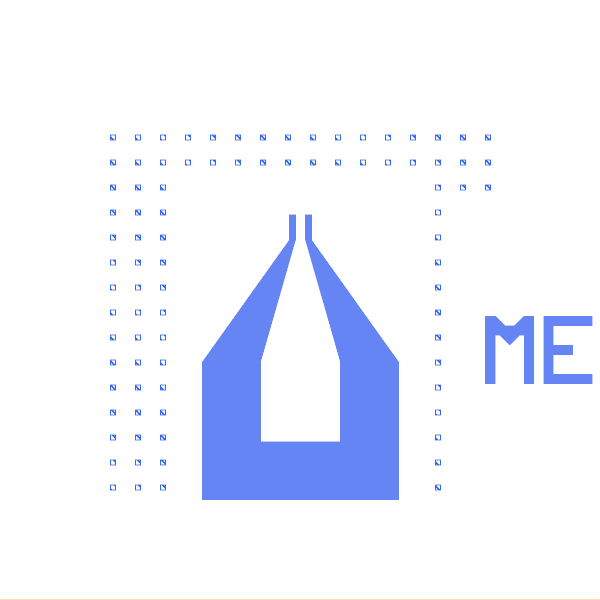

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `T_west`, `T_east`, `T_NE`, `T_NW`, `T_SW`, `T_SE`.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s2_pads.png')

In [6]:
with d.batch():
    lp = {n: d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e)
          for n, x, y, r, e in (("T_west", -1500, 0, 0, "w"), ("T_east", 1500, 0, 180, "e"),
                                ("T_NE", 500, 1000, -90, "n"), ("T_NW", -500, 1000, -90, "n"),
                                ("T_SW", -500, -1000, 90, "s"), ("T_SE", 500, -1000, 90, "s"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "T_SW.tie")
layout_step(d, OUT / "iswap3_xmon_tc_s2_pads.png", box=(px - 300, -2250, px + 300, -1650), size=(600, 600), width=300)

## Design 3 · Readout: the through line and the three open ends

The readout line needs no qubit, so it comes first. **The through line** `tline` runs from `T_east` to `T_west` along
Metal's arch over the chip (10 / 6 µm CPW, 20 µm fillet), ending at the west tie (Metal's line overshoots it and
doubles back; see the title). **The open ends:** three `metal:OpenToGround`s beside it terminate the two qubits' 2 mm
readout meanders (`open2`, `open3`, east and west) and the coupler's 1.5 mm meander (`open1`, north). The readout ends
couple to the through line only through their 125 µm gap to it (≈ 0.1 fF): not in the LOM.

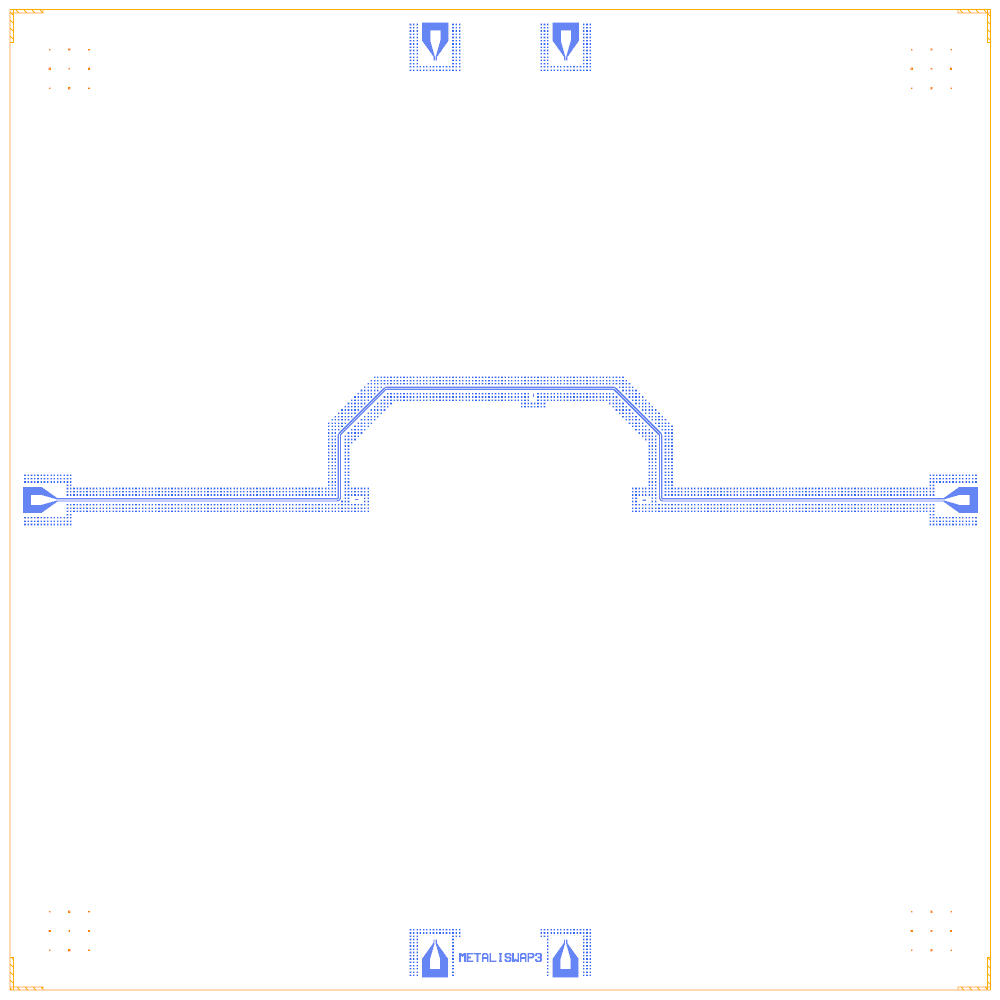

**On the chip so far:** 6 pads · 0 qubits · 3 other components · 1 routes · 0 declared couplings. **This step added** 3 component(s) `open1`, `open2`, `open3` and 1 route(s) `tline`.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s3_readout_line.png')

In [7]:
with d.batch():
    otg = {n: d.add(n, "metal:OpenToGround", at=P(x, y), rot=r)
           for n, x, y, r in (("open1", 250, 800, 0), ("open2", 1100, 0, -90), ("open3", -1100, 0, 90))}
    # the east-west through line (Metal's arch, ending at the west tie)
    d.route("tline", lp["T_east"].tie, lp["T_west"].tie, r=20, **CPW,
            nodes=PP([(1225, 0), (1225, 500), (871.45, 853.55), (-878.55, 853.55), (-1232.11, 500), (-1232.11, 0)]))
layout_step(d, OUT / "iswap3_xmon_tc_s3_readout_line.png", size=(1000, 1000), width=400)

## Design 4 · Qubit placement: two crossmons with PDK SQUIDs

**The qubits.** `metal:TransmonCrossFL` (a cross with a flux T-line), Q1 at (300, 0) and Q2 rotated 180° at
(−300, 0), each with a gap-type connector `b` (north) and a claw `c` (west, towards the readout). They are flux
tunable, so each gets a **PDK SQUID** (`trilayer_junction(..., squid=True)`: two 0.25 × 0.6 µm trilayer junctions,
45 kΩ in parallel, L_J 6.73 nH at zero flux, C_J 15 fF); `junction=` carries L_J / C_J to the LOM. The tutorial gives
no target frequency (estimate ≈ 5.8 GHz with the PDK SQUID; the assumed 10 nH gave 5.08 GHz).

**The claw vs the arm (PDK `pdk_claw`).** A `TransmonCross` claw longer than the arm reach (arm + ground spacing −
half the arm width = 195 µm with the defaults) runs into the side arms' gap; the fix is a longer
`cross_length`. The claws here are Metal's default 30 µm: far inside.

The junction cell prepares the PDK SQUID once (`SQ_PARAMS`, `SQUID`); the coupler (Design 6) gets the same one.

SQUID: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['b', 'c', 'flux_line', 'squid_a', 'squid_b']


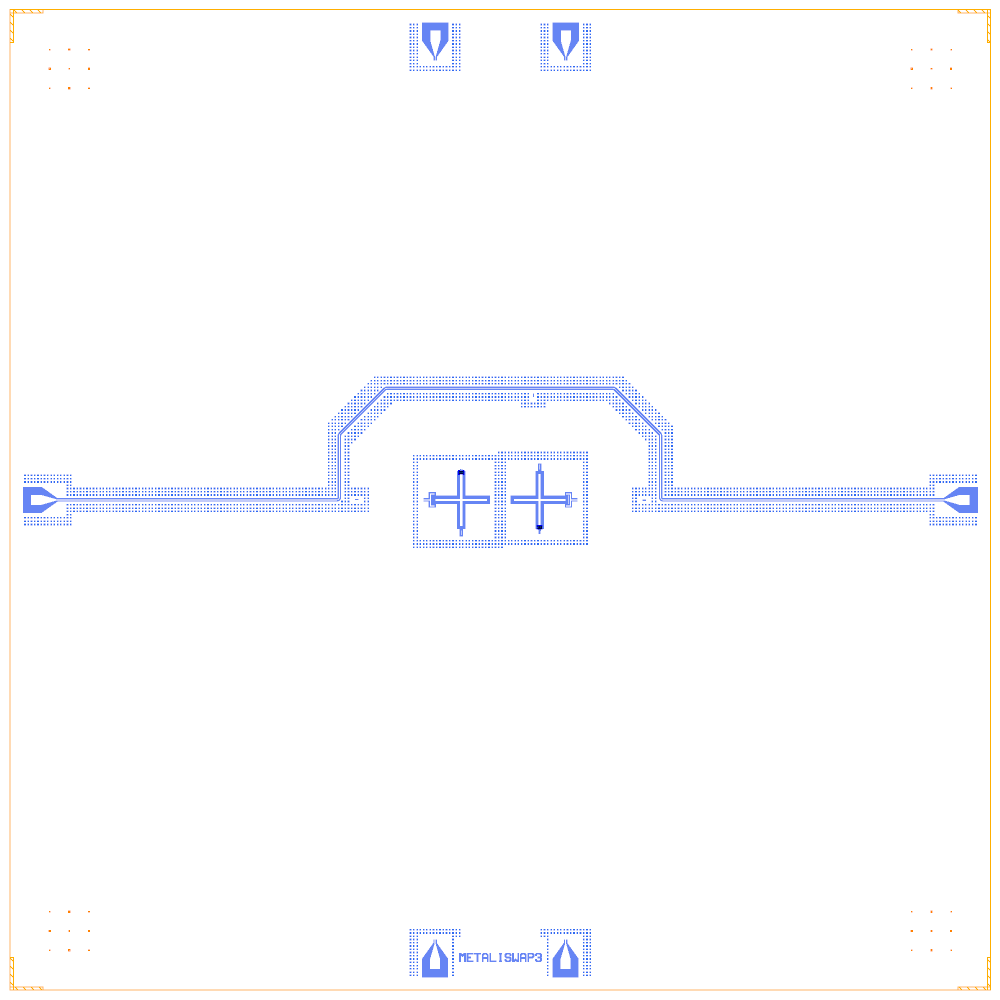

**On the chip so far:** 6 pads · 2 qubits · 3 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s4_qubits.png')

In [8]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
# flux-tunable qubits / couplers: a Quantcore SQUID of two junctions, R_n 45 kΩ in parallel (L_J 6.73 nH at zero
# flux, C_J 15 fF); SQ_PARAMS = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": 6.73}}
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
print("SQUID:", SQ_PARAMS, SQUID)
with d.batch():
    pads = {"b": {"connector_location": "90", "connector_type": "1"},
            "c": {"connector_location": "180", "connector_type": "0"}}
    q1 = d.add("Q1", "metal:TransmonCrossFL", at=P(300, 0), junction=SQUID, **SQ_PARAMS, connection_pads=pads)
    q2 = d.add("Q2", "metal:TransmonCrossFL", at=P(-300, 0), rot=180, junction=SQUID, **SQ_PARAMS, connection_pads=pads)
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "iswap3_xmon_tc_s4_qubits.png", size=(1000, 1000), width=400)

## Design 5 · Readout: the two open 2 mm meanders

Each qubit's claw `c` (west for Q2, east for Q1 after its 180° turn) gets a 2 mm open meander to its `OpenToGround`
beside the through line: Metal's `RouteMeander` corner points (`right`; `coupler_left` is its point mirror), 90 µm
spacing, 40 µm fillet. Open at the claw and at the open end, each is a λ/2 far above the qubits (≈ 29 GHz in the LOM),
as the source's lengths are: the source's "readouts" are structural.

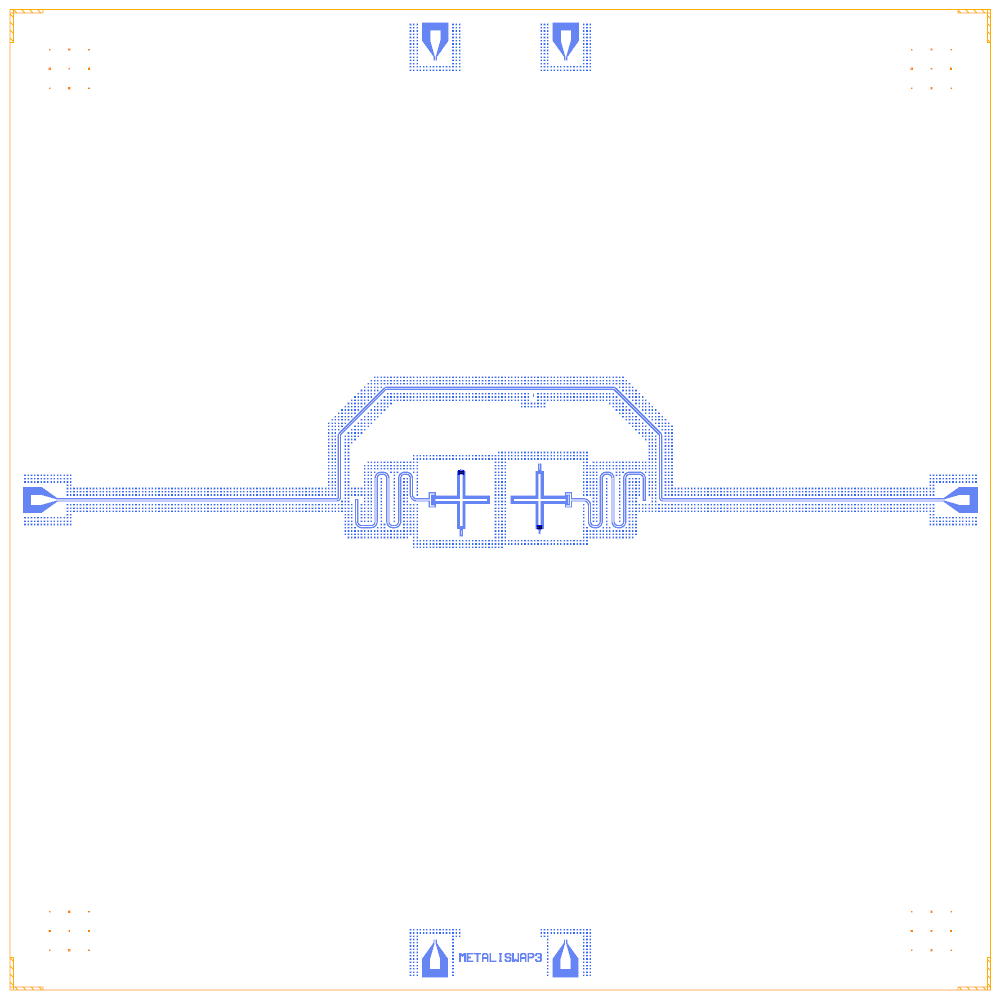

**On the chip so far:** 6 pads · 2 qubits · 3 other components · 3 routes · 0 declared couplings. **This step added** 2 route(s) `coupler_right`, `coupler_left`.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s5_readouts.png')

In [9]:
with d.batch():
    right = [(681, 0), (681, -204.44), (771, -204.44), (771, 204.44), (861, 204.44), (861, -204.44), (951, -204.44),
             (951, 204.44), (1100, 204.44)]
    d.route("coupler_right", q1.c, otg["open2"].open, r=40, nodes=PP(right), **CPW)
    d.route("coupler_left", q2.c, otg["open3"].open, r=40, nodes=PP([(-x, -y) for x, y in right]), **CPW)
layout_step(d, OUT / "iswap3_xmon_tc_s5_readouts.png", size=(1000, 1000), width=400)

## Design 6 · Coupling: the tunable coupler, its meander, the declared couplings

**The coupler.** `metal:TunableCoupler01` above the inner arms (`a_height` 100 µm), with its own PDK SQUID. Its `Control` claw gets the 1.5 mm open meander `coupler_mid` to `open1` (Metal's corner points).

**Couplings no route carries** (coplanar-strip estimates, rough; the Q3D job `Q1_TC_Q2` replaces them): the coupler
island's bottom bar over each qubit's inner arm (`Cg_Q1_TC`, `Cg_Q2_TC`), and the two inner arm tips end-on across
200 µm (`Cg_Q1_Q2`). The second picture zooms on the core.

C(TC ↔ Q): 2.28 fF;  C(Q1 ↔ Q2): 1.56 fF (estimates)
TC ports: ['Control', 'Flux', 'squid_a', 'squid_b']


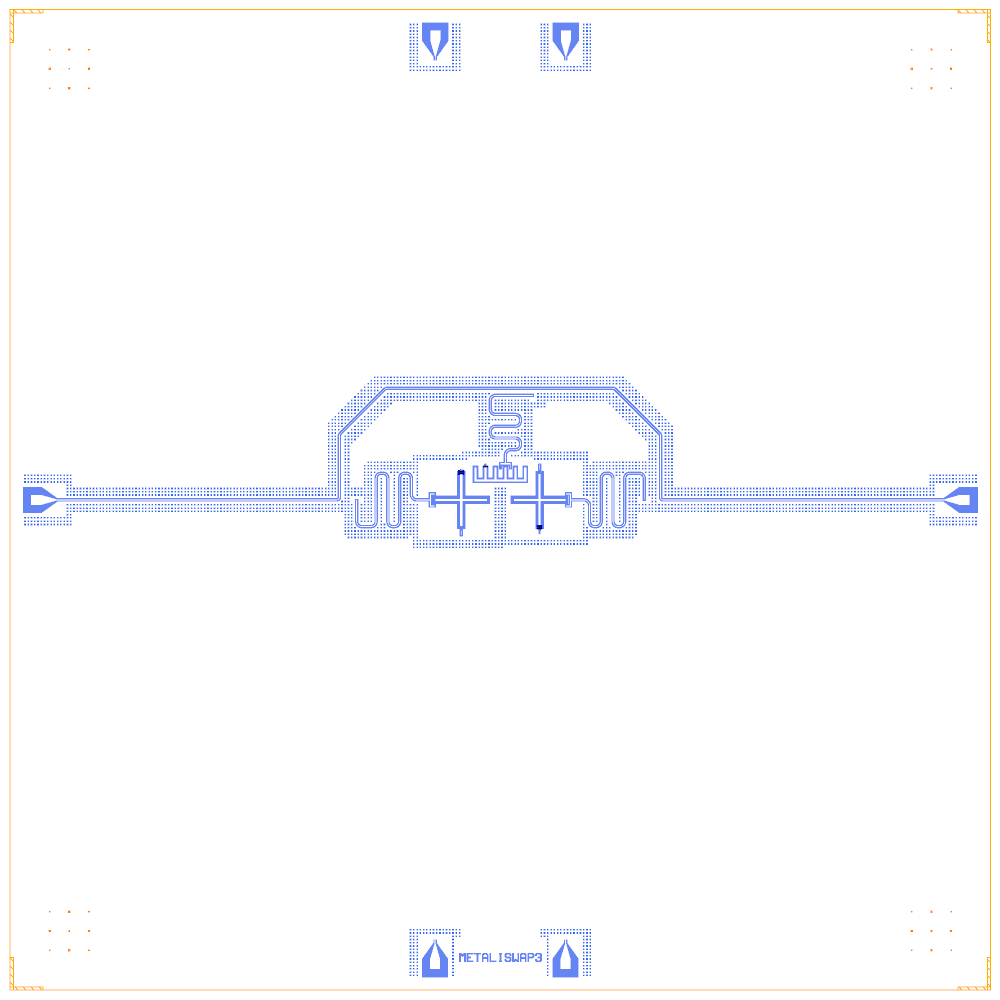

**On the chip so far:** 6 pads · 2 qubits · 4 other components · 4 routes · 3 declared couplings. **This step added** 1 component(s) `TC` and 1 route(s) `coupler_mid`.

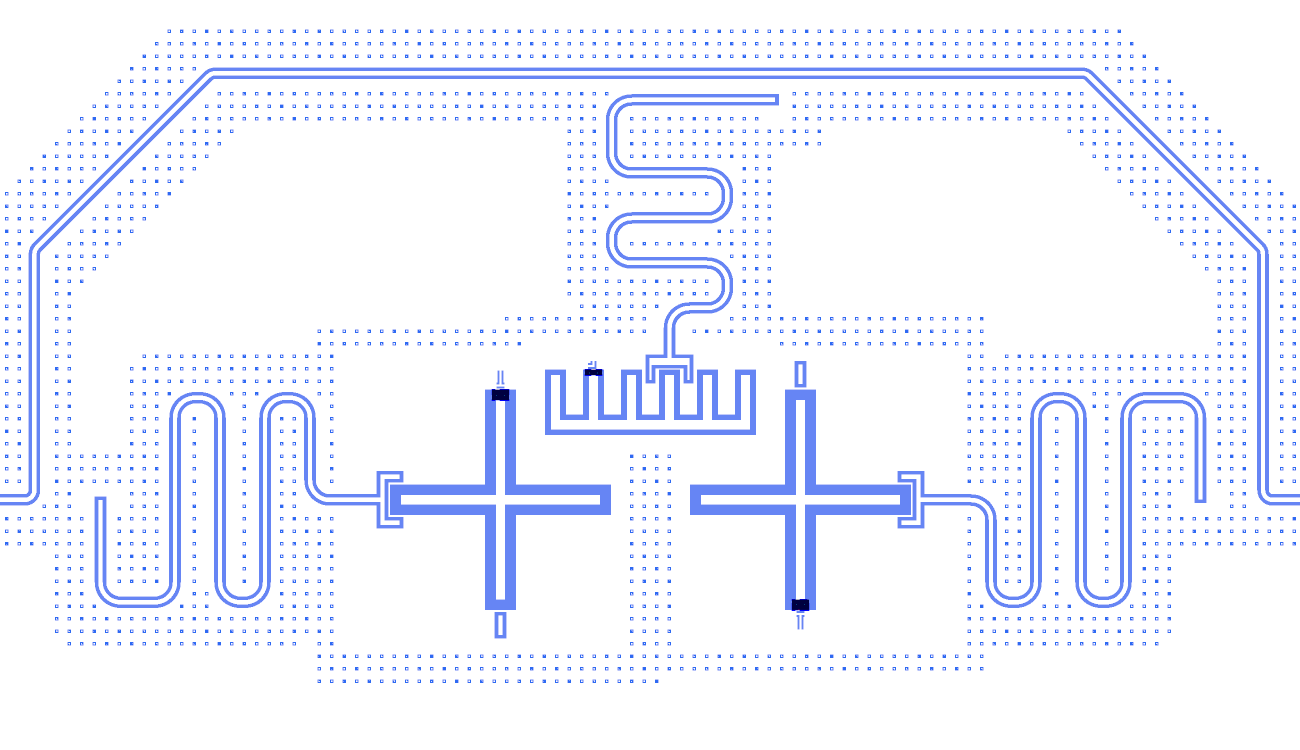

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_parts.png')

In [10]:
EPS = est.substrate_eps(get_pdk())
# coupler island (10 µm bottom bar, ±206 µm wide, 132 µm above the axis) over a qubit's inner arm (20 µm wide, tip at
# ±100 µm): ≈ 106 µm overlap, ≈ 120 µm apart with the ground strip between the two pockets (screening 0.5, rough)
C_TC = round(est.coplanar_coupling(106, 20, 10, 120, EPS, screening=0.5), 2)
# inner arm tips end-on: 20 µm facing width (cross_width), 200 µm apart, 200 µm deep each
C_QQ = round(est.coplanar_coupling(20, 200, 200, 200, EPS), 2)
print("C(TC ↔ Q):", C_TC, "fF;  C(Q1 ↔ Q2):", C_QQ, "fF (estimates)")
with d.batch():
    tc = d.add("TC", "metal:TunableCoupler01", at=P(0, 150), a_height=100, junction=SQUID, **SQ_PARAMS)
    d.route("coupler_mid", tc.Control, otg["open1"].open, r=40, **CPW,
            nodes=PP([(38, 384), (153.81, 384), (153.81, 474), (-77.81, 474), (-77.81, 564), (153.81, 564),
                      (153.81, 654), (-77.81, 654), (-77.81, 800)]))
    # couplings no route carries (estimates, see the markdown)
    d.couple("Cg_Q1_TC", "Q1", "TC", C_fF=C_TC, note="coupler island end over Q1's inner arm (CPS estimate)")
    d.couple("Cg_Q2_TC", "Q2", "TC", C_fF=C_TC, note="coupler island end over Q2's inner arm (CPS estimate)")
    d.couple("Cg_Q1_Q2", "Q1", "Q2", C_fF=C_QQ, note="inner arm tips end-on, 200 µm (CPS estimate)")
print("TC ports:", sorted(tc.ports))
layout_step(d, OUT / "iswap3_xmon_tc_s6_coupling.png", size=(1000, 1000), width=400)
snap(d, OUT / "iswap3_xmon_tc_step_parts.png", box=P(-1300, -500) + P(1300, 1000), size=(1300, 750), width=520)

## Design 7 · Routing: the four control lines, two over the arch

Straight lines to the four north / south pads (Metal `RouteStraight`, 250 µm leads; a 20 µm fillet at the 45° corners):
Q1's flux line to `T_SE` (`cpw_1`), Q2's claw `b` to `T_SW` (`cpw_2`), Q1's claw `b` to `T_NE` (`cpw_3`) and the
coupler's flux line to `T_NW` (`cpw_4`). The two north lines cross the through line's arch (y = 853.55 µm, Metal
frame): a waypoint with `airbridge=True` (`AB`) puts a KQC airbridge there (none in the source, where they short). The
pads sit at the edge, so each line's last lead is 2–2.5 mm longer than in the source.

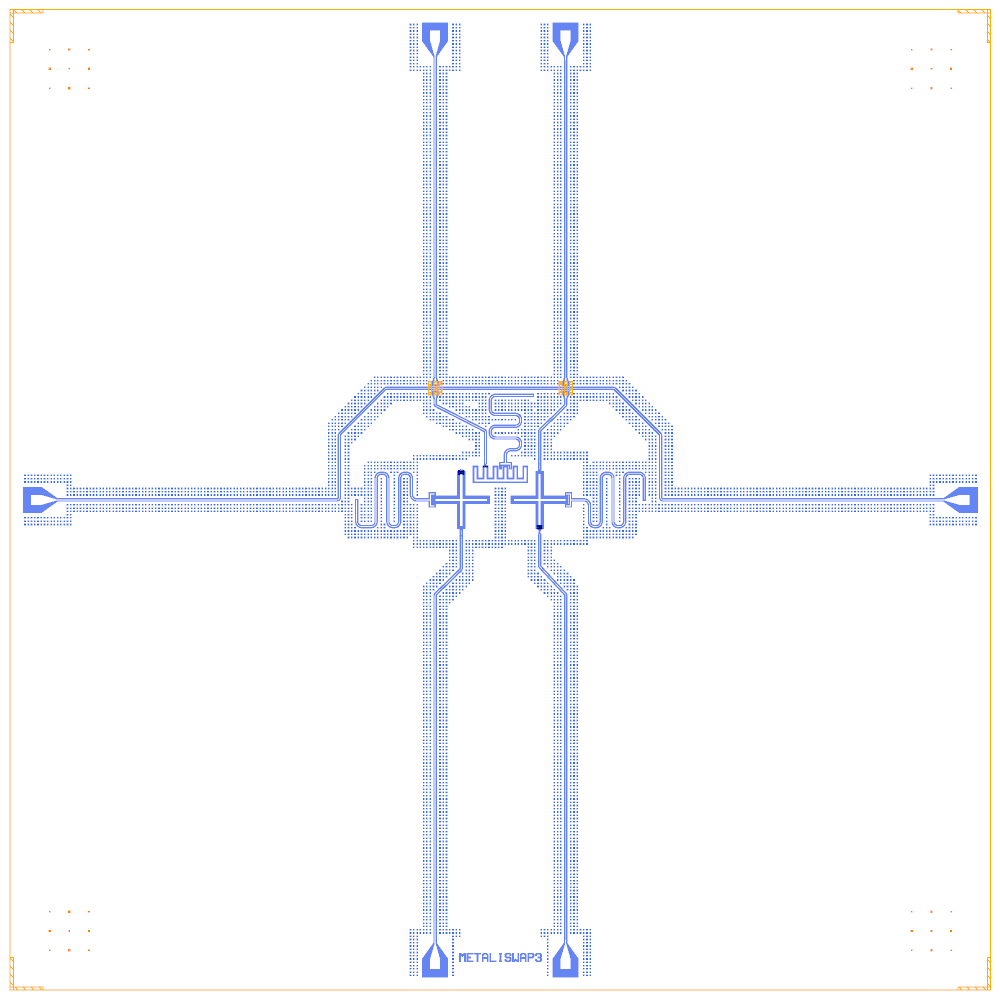

**On the chip so far:** 6 pads · 2 qubits · 4 other components · 8 routes · 3 declared couplings. **This step added** 4 route(s) `cpw_1`, `cpw_2`, `cpw_3`, `cpw_4`.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_s7_control.png')

In [11]:
with d.batch():
    # straight lines to the bottom pads (Metal RouteStraight, 250 µm leads)
    d.route("cpw_1", q1.flux_line, lp["T_SE"].tie, r=20, nodes=PP([(300, -508.5), (500, -725)]), **CPW)
    d.route("cpw_2", q2.b, lp["T_SW"].tie, r=20, nodes=PP([(-300, -531), (-500, -725)]), **CPW)
    # the two north lines cross the through line's arch (y = 853.55): an airbridge each (none in the source)
    AB = lambda x: d.waypoint(P(x, 853.55), airbridge=True)
    d.route("cpw_3", q1.b, lp["T_NE"].tie, r=20, nodes=PP([(300, 531), (500, 725)]) + [AB(500)], **CPW)
    d.route("cpw_4", tc.Flux, lp["T_NW"].tie, r=20, nodes=PP([(-114, 527.5), (-500, 725)]) + [AB(-500)], **CPW)
layout_step(d, OUT / "iswap3_xmon_tc_s7_control.png", size=(1000, 1000), width=400)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: the qubit / coupler core `Q1_TC_Q2` (Q3D C-matrix; the box cuts
each line once) and `Q1_read`, Q1 with its open meander (eigenmode).

**Centring.** The PDK wants the chip content centred in the die. The die is already centred on the source's chip and the pads now
sit symmetrically on all four edges, so `center_in_die` finds the content centred (a shift under its 50 µm tolerance
is not applied) and moves nothing. `X0, Y0` follow the shift, so `P(x, y)` still maps Metal positions for the snapshots.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the open ends, the through line and the meanders were added before the control
lines here), so `git diff` stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/iswap3_xmon_tc.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer iswap3_xmon_tc: 12 instances, 8 routes, live=False> → examples\designs\metal\iswap3_xmon_tc.json
route lengths (µm): {'tline': 8002.3, 'coupler_right': 2000.0, 'coupler_left': 2000.0, 'coupler_mid': 1500.0, 'cpw_1': 3183.3, 'cpw_2': 3166.8, 'cpw_3': 3166.8, 'cpw_4': 3318.6}


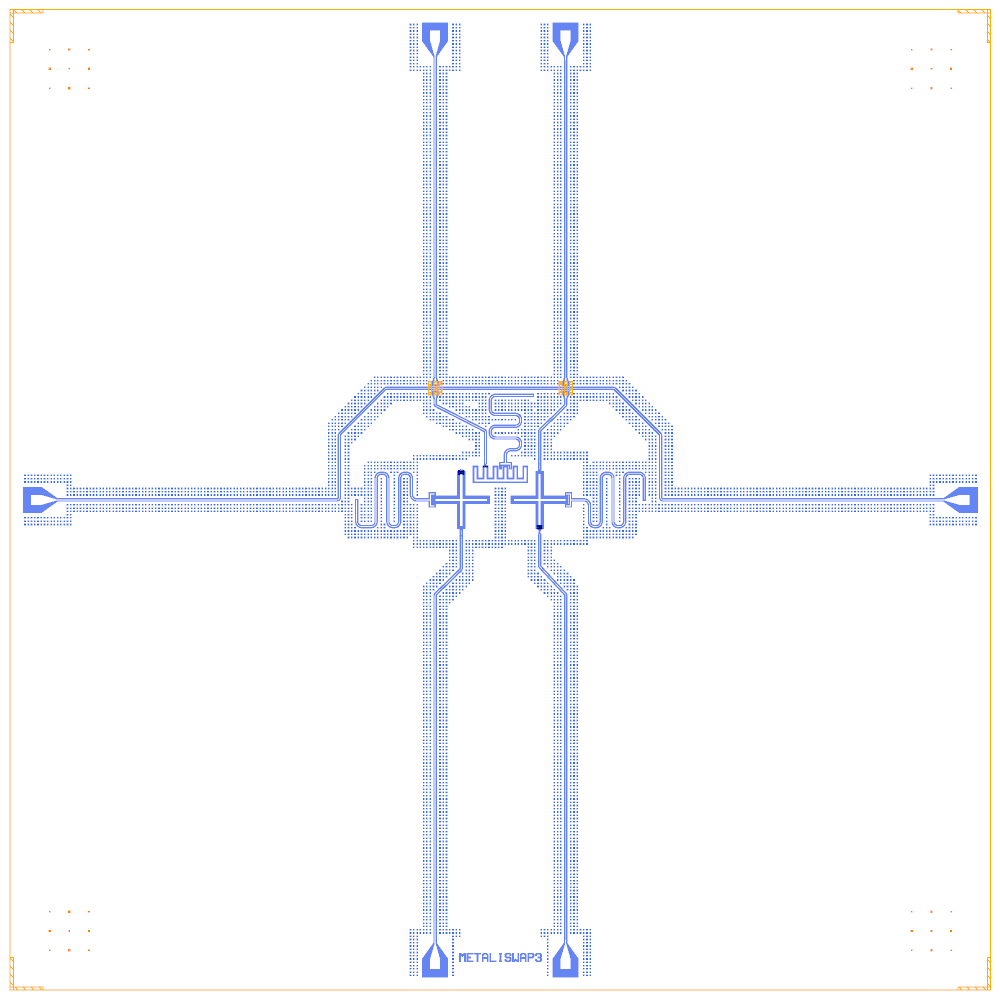

**On the chip so far:** 6 pads · 2 qubits · 4 other components · 8 routes · 3 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_routes.png')

In [12]:
# FEM boxes: the qubit / coupler core (cuts each line once), and the right readout with its open end and the line
d.sim_group("Q1_TC_Q2", ["Q1", "Q2", "TC"], margin_um=40, analyses=["q3d_cmatrix"])
d.sim_group("Q1_read", ["Q1", "coupler_right", "open2"], margin_um=40, analyses=["eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
X0, Y0 = X0 + shift[0], Y0 + shift[1]            # keep P(x, y) = Metal → Designer after the shift
DESIGN, same = save_design(d, OUT / "iswap3_xmon_tc.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "iswap3_xmon_tc_step_routes.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; `dangling_port` warnings for the junction attachment points `squid_a` /
`squid_b` of Q1, Q2 and TC (drawn by the cells, not route ends) and Q2's unused flux line; two `overlap` warnings,
the coupler's bounding box over Q1's and Q2's (it sits above their inner arms, as in the source; the metal does not
touch). **No PDK design warnings:** the six pads are at 100 µm (`pad_edge`); each PDK SQUID (two 90 kΩ junctions)
is 45 kΩ in parallel, inside the 40–50 kΩ window (`pdk_rn` checks the device); no targets (`pdk_fq`); 30 µm claws
on 200 µm arms (`pdk_claw`).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: `TransmonCrossFL` → a grounded cross island with its SQUID, a node
per claw, the flux line as a control; `TunableCoupler01` → a grounded island + SQUID, the `Control` claw as a node,
`Flux` as a control. Each claw → open-end meander is a λ/2 `TLres` (open at the claw and at the `OpenToGround`: 2 mm ≈
32 GHz, 1.5 mm ≈ 43 GHz, far above the qubits, as the source's lengths are); Q2's claw `b` line ends on its 50 Ω pad.
The three `d.couple` capacitances join the coupler island to both qubits and the qubits to each other.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "TC."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit and the coupler with its open meander, then Q1–coupler–Q2 (static ZZ). The meanders are λ/2 far above the
qubits and couple to the through line only geometrically, so they are not readouts in the LOM (κ 0, χ small). From the v1 run:

- Q1 / Q2 with the PDK SQUID ≈ 5.8 GHz (the assumed 10 nH gave 5.08 GHz); the coupler ≈ 7.9 GHz at zero flux.
- The two qubits are identical, so their modes hybridise through the coupler (and the direct arm coupling): ZZ is
  not defined for degenerate qubits. Both couplings are the rough estimates of Design 6.

In [ ]:
read = {"Q1+coupler_right": ["Q1", "coupler_right", "open2"], "Q2+coupler_left": ["Q2", "coupler_left", "open3"],
        "TC+coupler_mid": ["TC", "coupler_mid", "open1"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
coupled = simulate_groups(d, {"Q1+TC+Q2": ["Q1", "TC", "Q2"]}, max_modes=3)
display(Markdown("**Q1–TC–Q2, QuCat normal modes:**\n\n" + modes_md(coupled["Q1+TC+Q2"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares the
open meanders; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each meander. From the v1
run the meanders sit at 29–40 GHz, far above the qubits (5.85 GHz, the coupler 7.9 GHz), and in the coupled group
the two identical qubits split into a symmetric / antisymmetric pair (5.89 / 5.97 GHz, 50 / 50).

In [ ]:
plot_lom({**results, **coupled}, OUT / "iswap3_xmon_tc_lom.png", title="iswap3: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step. Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here Q1's arm length `cross_length`, 200 → 180 µm (the knob the PDK's `pdk_claw` fix turns the other way) — and re-run
the LOM of Q1 with its open meander. Shorter arms mean a smaller C_Σ: f_q and |α| go up. (A longer arm would push the
claw `c` into the first 90° turn of `coupler_right`, which starts on Metal's corner point 381 µm east of Q1's centre:
the router then reports that the straight segment cannot fit.)

In [ ]:
d2 = design_copy(DESIGN)
d2["Q1"].set(cross_length=180)                   # 200 µm (Metal default) → 180 µm
res2 = simulate_groups(d2, {"Q1+coupler_right": read["Q1+coupler_right"]})
display(Markdown(params_delta_md({"Q1+coupler_right": results["Q1+coupler_right"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs: a **Q3D C-matrix** for the two qubits and the coupler (it replaces the three assumed couplings; the
box cuts each line once) and an **eigenmode / EPR** job for Q1 with its open meander (the lines the box cuts end in 50 Ω; in the v1
export they were Q1's flux line `cpw_1` and its north line `cpw_3`: the through line passes just outside the box). In the v1 run the exporter warned that it could not draw the
coupler's junction port ("Unable to create polygon for port …"); `TC.island` is still a net of the C-matrix job.
(The 2026-11-18 port change concerns lines leaving a box at an angle, not this junction port: check the
export's notes.)

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q1_TC_Q2"])
jobs_eig = export_sims(DESIGN, ["Q1_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the core `Q1_TC_Q2`: both cross islands, the coupler island and the claws, with the lines the box
cuts as nets. It measures the three couplings Design 6 declares from estimates (coupler ↔ each qubit, the arm tips).
Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves the
job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q1_read` box in HFSS eigenmode: Q1's SQUID is a lumped L_J ‖ C_J sheet, the lines the box cuts end in 50 Ω, so
the qubit mode's Q is that loading. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns
the junction's energy participation into Q1's dressed f_q and α, to compare with the LOM.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Not exported for this chip: the readout meanders end open beside the through line and no box holds both, so there is
no S21 of a readout to drive (the meanders' coupling to the line is the ≈ 0.1 fF of their 125 µm gap).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's Q1 frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": results["Q1+coupler_right"].params.get("Q1.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "iswap3_xmon_tc_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: Q1's mode is the one its SQUID participates in most; f_q is pyEPR's dressed
frequency, α its self-Kerr. The open meander is not a readout (≈ 29 GHz), so `epr_values` gets a placeholder readout
and only Q1's values are kept.

In [ ]:
fem_q1 = {}
if keep_eig["Q1_read"]:
    fem_q1 = {k: v for k, v in epr_values(keep_eig["Q1_read"], {"Q1": "none"}, {"none": 0.0}).items() if k.startswith("Q1.")}
if fem_q1:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q1.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q1's f_q and α from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each LOM 1 group by the `Q1_TC_Q2` job's
C-matrix values (matched by net name) and the same LOM runs again: f_q and α of each qubit and the coupler, and the
coupled `Q1+TC+Q2` group, whose couplings are then measured instead of estimated. **FEM directly:** Q1's eigenmode
values (Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
if keep_q3d.get("Q1_TC_Q2"):
    for g, sel in {**read, "Q1+TC+Q2": ["Q1", "TC", "Q2"]}.items():
        lom_p = (coupled if g in coupled else results)[g].params
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d["Q1_TC_Q2"]), max_modes=3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), "LOM on the Q3D C-matrix") for k, v in lom_p.items()
                 if k.endswith(("f_q_GHz", "alpha_MHz"))]
lom_q1 = results["Q1+coupler_right"].params
rows += [(k, lom_q1.get(k), v, "Q1 eigenmode + pyEPR") for k, v in fem_q1.items() if k in lom_q1]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the Q3D "
          "C-matrix (single and coupled groups) and next to Q1's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets; its two crossmons are identical (from the v1 run: 5.85 GHz dressed each) and hybridise
50 / 50 through the coupler (LOM 1). This notebook sets one target as an exercise that detunes them: **Q2 at 5.65 GHz**
(dressed, at zero flux: the SQUID's sweet spot). It is reachable inside the PDK junction window: by the transmon
formula (E_C ≈ |α| ≈ 0.2 GHz from the v1 run) Q2's SQUID goes from L_J 6.73 nH to ≈ 7.2 nH, R_n ≈ 48 kΩ in parallel.

`loop.feedback` tunes qubit–readout pairs, and this chip's meanders are not readouts (λ/2 at ≈ 29 GHz, κ 0). So the
step is a first-order rule in the notebook: f_q ∝ L_J^−1/2, so **L_J ← L_J · (f_now / f_target)²** (`rule_step`,
exponent −0.5), kept inside the PDK window (`pdk_lj_bounds`: R_n 40–50 kΩ). The new SQUID is drawn
(`trilayer_junction(..., lj_nH=..., squid=True)` sizes both fingers and gives C_J) on a copy of the design
(`design_copy`), and Q2 is measured again in its LOM 1 group (`Q2+coupler_left`). Only L_J moves, so the capacitances
do not: when the `Q1_TC_Q2` Q3D job is kept (Simulate 2) its C-matrix fills every revision (the FEM point), otherwise
the LOM estimates do.

In [ ]:
from quantcore_circuits.assembly.drc import check

Q_T, F_T, TOL = "Q2", 5.65, 0.020                # the exercise target: Q2 at 5.65 GHz ± 20 MHz (dressed, zero flux)
G_T = read["Q2+coupler_left"]                     # the LOM 1 group that measures it
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("Q1_TC_Q2")                   # a kept Q3D job: its C-matrix holds for every revision


def f_q2_of(lj, it):
    """Revision it: Q2's SQUID drawn for lj nH on a copy, saved; its dressed f_q (LOM, on the kept C-matrix)."""
    d_k = design_copy(DESIGN, f"_rev{it}")
    jp, jj = trilayer_junction("metal:TransmonCrossFL", lj_nH=lj, squid=True)
    d_k[Q_T].set(junction=jj, **jp)
    path = d_k.save(Path("build") / "iswap3_xmon_tc_target" / f"rev{it}.json")
    return simulate(fill(d_k.lom(select=G_T).model, d_k.design, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz"), path


LJ0 = d.data["instances"][Q_T]["junction"]["Lj_nH"]
F0 = simulate(fill(d.lom(select=G_T).model, DESIGN, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz")
LJ1 = min(max(rule_step(LJ0, F0, F_T, -0.5), LO), HI)
F1, REV1 = f_q2_of(LJ1, 1)
display(Markdown(before_after_md({"Q2 L_J (nH)": LJ0, "Q2 f_q (GHz)": F0}, {"Q2 L_J (nH)": LJ1, "Q2 f_q (GHz)": F1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (F1 - F_T):+.1f} MHz · revision 1: {REV1} · DRC:",
      "clean" if check(str(REV1)).ok else "ERRORS")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the new L_J, its LOM runs, and the next step uses the exponent of
the last two points (a secant in log–log), inside the PDK window, until Q2 is within 20 MHz or `MAX_ITER` steps are
made. The table shows each iteration (on: FEM when the C-matrix filled it, else LOM), the plot the residual in
tolerances (on target below 1). The last cell line re-runs the coupled group on the last revision: the two qubit modes
should no longer be a 50 / 50 pair.

In [ ]:
history = rule_iterate(f_q2_of, f"{Q_T}.f_q_GHz", f"{Q_T}.junction.Lj_nH", LJ0, F_T, TOL, -0.5, max_iter=MAX_ITER,
                       start=(F0, DESIGN), fem=FEM0 is not None, bounds=(LO, HI))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "iswap3_xmon_tc_iterate.png")
last = history[-1]["design"]
print("last design:", last, "· DRC:", "clean" if check(str(last)).ok else "ERRORS", "· on target:", history[-1]["on_target"])
d_last = design_copy(last, "_last")
display(Markdown("**Q1–TC–Q2 on the last revision, QuCat normal modes:**\n\n" + modes_md(
    simulate_groups(d_last, {"Q1+TC+Q2": ["Q1", "TC", "Q2"]}, max_modes=3)["Q1+TC+Q2"])))

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The two airbridges export to 300/0
+ 301/0.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's last screenshot; the pads now on the die edges); the two crossmons with the
coupler above their inner arms; a SQUID; the airbridge where Q1's north line crosses the arch; the **fab mask** of
the core (1/0 etch with the PDK cheese band, the 3/0 keep-out, the junction layers); and the die frame's south-west
corner (dicing L on 1000/0, alignment grid on 1001/0).

In [ ]:
show_snapshot(d, OUT / "iswap3_xmon_tc.png", size=(1400, 1400))
show_snapshot(d, OUT / "iswap3_xmon_tc_core.png", box=P(-450, -300) + P(450, 350), size=(1400, 1010), width=520)
show_snapshot(d, OUT / "iswap3_xmon_tc_jj.png", box=P(260, -230) + P(340, -170), size=(800, 600), width=300)
show_snapshot(d, OUT / "iswap3_xmon_tc_bridge.png", box=P(400, 780) + P(600, 930), size=(800, 600), width=300)
snap_file(Path("build") / "iswap3_xmon_tc_fab.oas", OUT / "iswap3_xmon_tc_cheese.png",
          box=P(-1300, -500) + P(1300, 1000), size=(1300, 750), width=520)
show_snapshot(d, OUT / "iswap3_xmon_tc_frame.png", box=(-1750, -2250, -850, -1350), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, every route's end pins and Metal corner points (the 1.5 / 2 / 2 mm open meanders, the arch), the sim groups |
| PDK changes | the 7.5 mm die with the QCT frame; sapphire stack; the six launchpads 100 µm from the W / E / N / S edges (were 1990–2490 µm in); trilayer SQUIDs (PDK) for both crossmons and the coupler; PDK cheese band; content centred (no shift needed) |
| differs | the pad leads are 2–2.5 mm longer; airbridges at the two arch crossings; the arch ends at the west tie; f_q ≈ 5.8 GHz with the PDK SQUID (the assumed 10 nH gave 5.08 GHz; from the v1 run) |
| PDK design warnings | none |
| layout | built in segments (die, pads, the through line with the open ends, the crossmons, their meanders, the coupler with its meander and couplings, the control lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target (Q2 5.65 GHz, detuning the identical pair) by a first-order SQUID L_J rule on design copies (no qubit–readout pair for `loop.feedback`); LOM, or the Q3D capacitances when the job is kept |
| open | the couplings are CPS estimates until the Q3D job is solved; the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`) |